In [1]:
import numpy as np
import matplotlib.pyplot as plt
from random import choice, seed

seed(42)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size'] = 12

g = 9.81 # m / s^2
dt = 0.001 # s

# Exercise 1

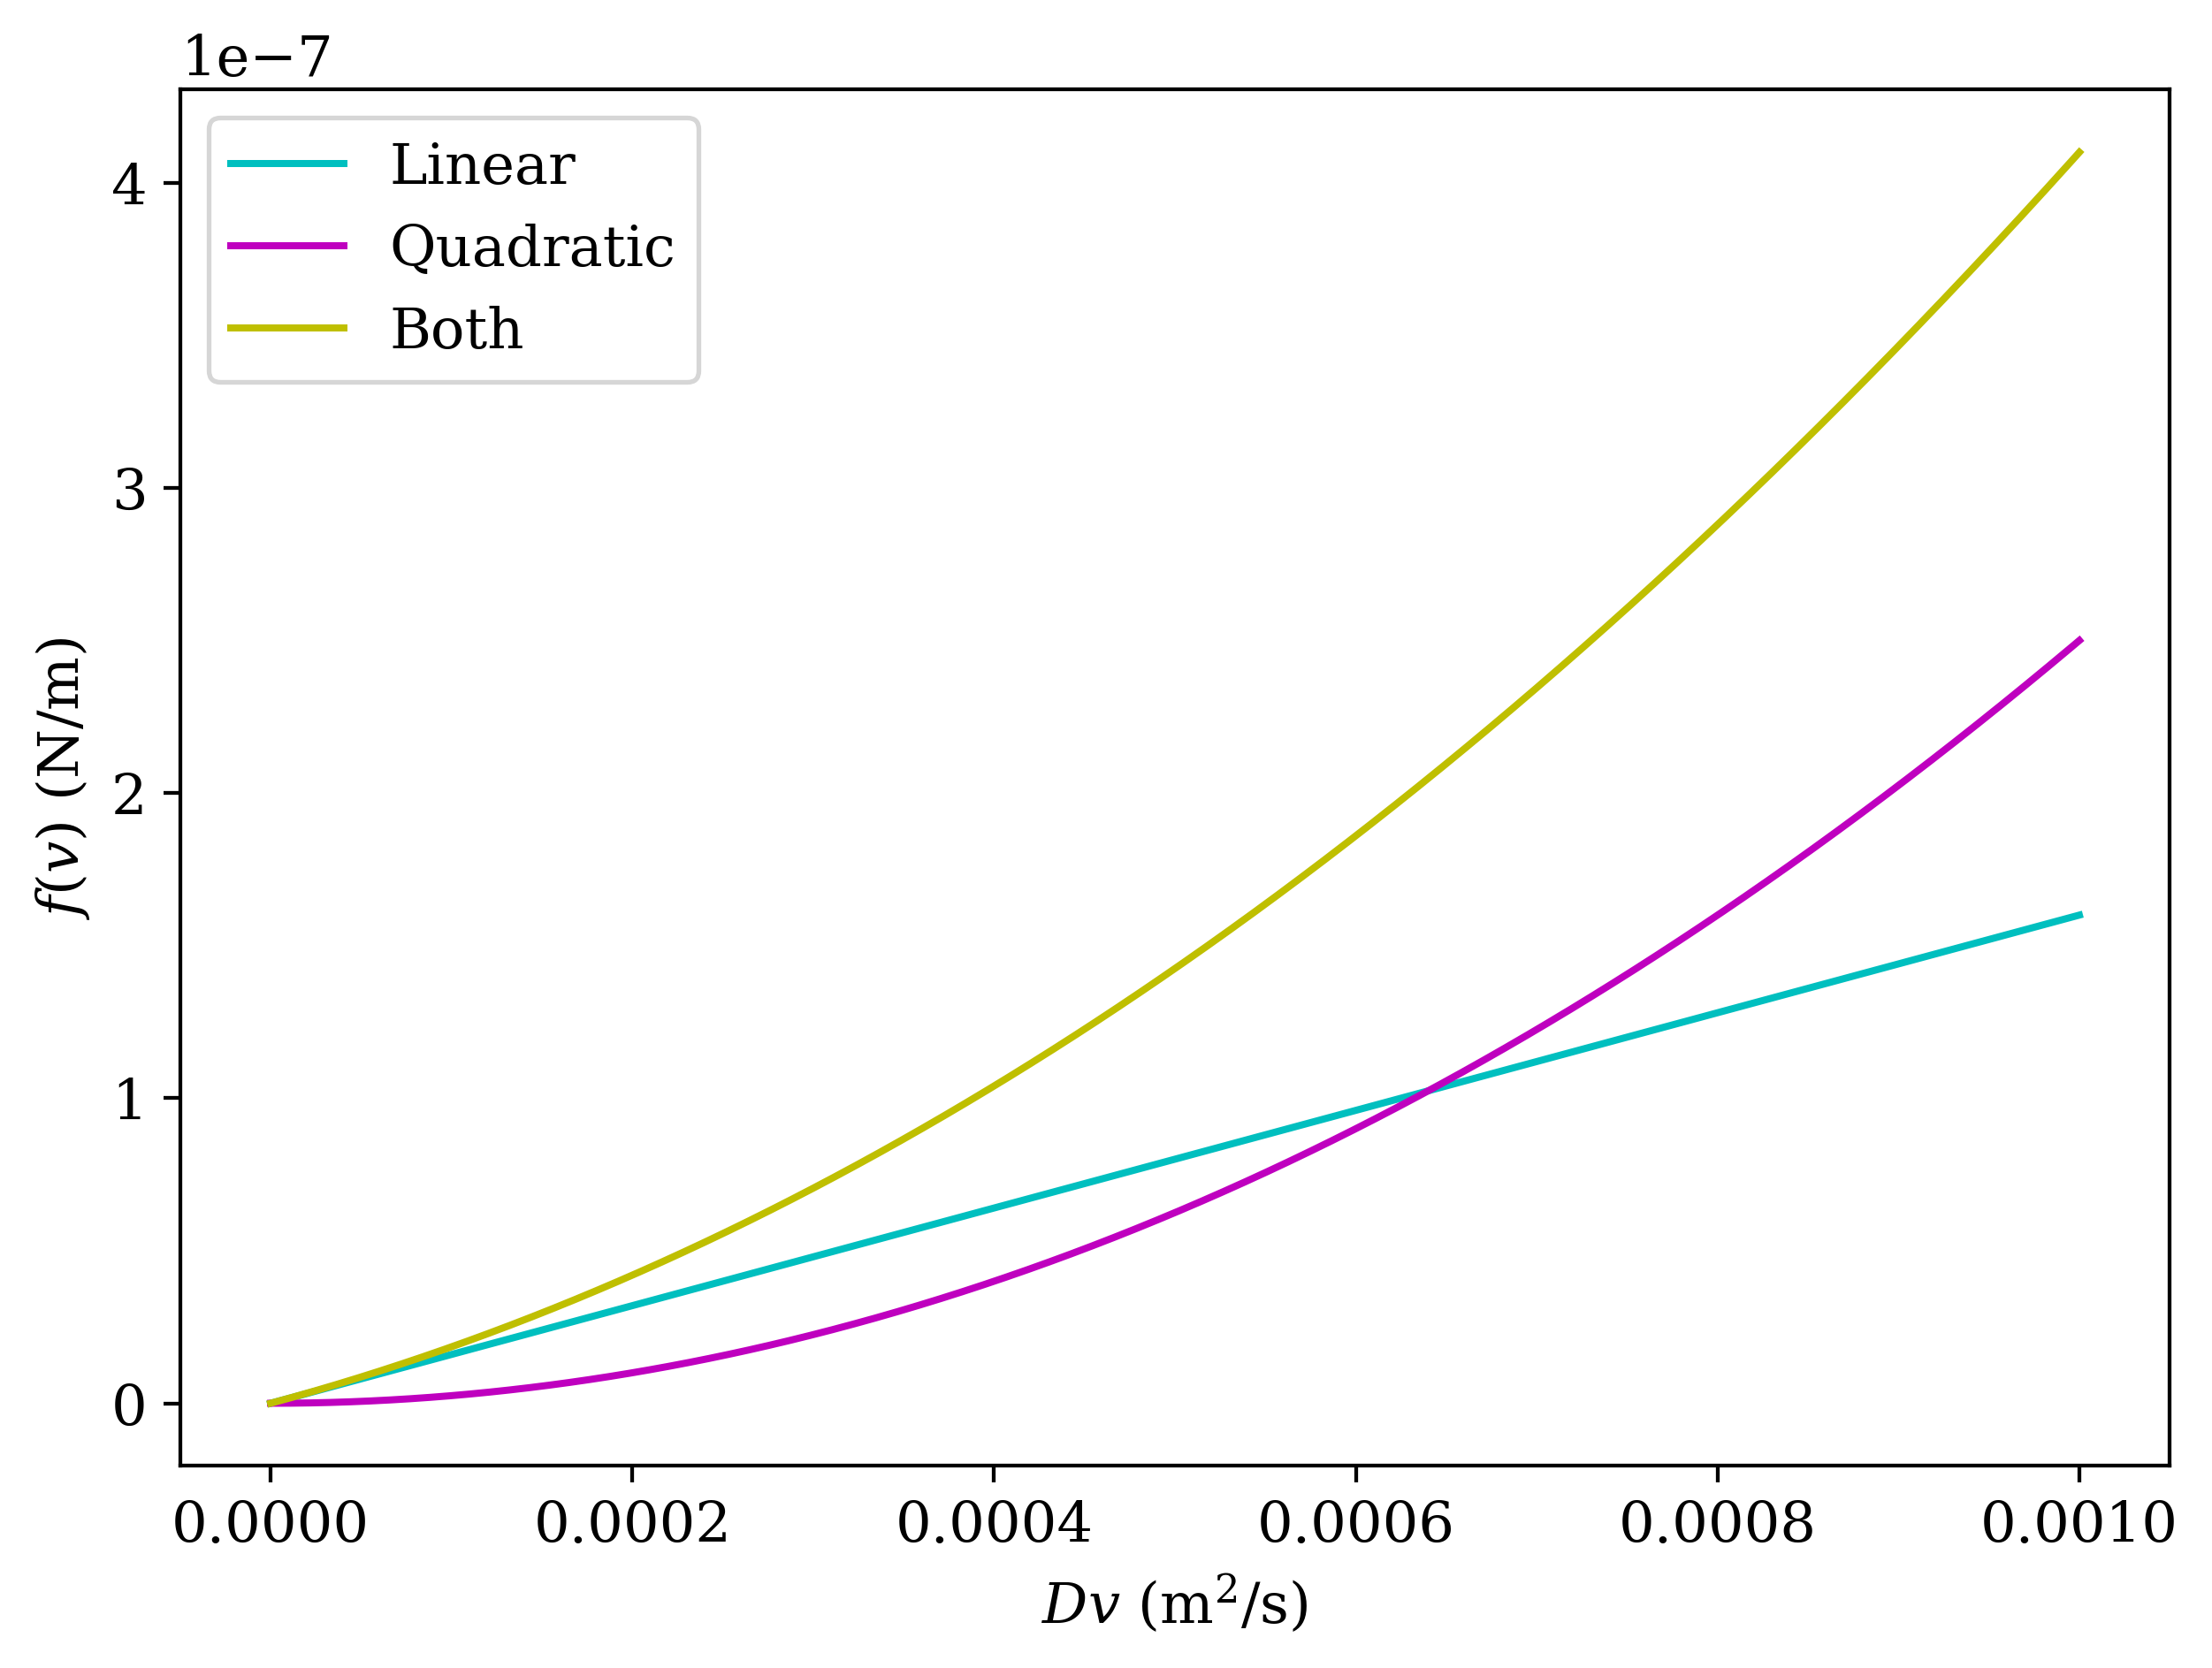


D = 0.07 m, v = 5 m/s
Linear contribution = 5.6e-05 N/m
Quadratic contribution = 0.0306 N/m
Total = 0.0307 N/m


D = 1.5e-06 m, v = 5e-05 m/s
Linear contribution = 1.2e-14 N/m
Quadratic contribution = 1.41e-21 N/m
Total = 1.2e-14 N/m


D = 0.001 m, v = 1 m/s
Linear contribution = 1.6e-07 N/m
Quadratic contribution = 2.5e-07 N/m
Total = 4.1e-07 N/m



In [2]:
B = 1.6e-4 # N s / m^2
C = 0.25 # N s^2 / m^4
D = 1 # m
vs = np.linspace(0, 0.001, num=1000) # m / s


"""Coefficient b - linear part of the resistance.
"""
def b(D, v):
  return B * D * v


"""Coefficient c - quadratic part of the resistance.
"""
def c(D, v):
  return C * D**2 * v**2


"""Coefficient f - total resistance.
"""
def f(D, v):
  return b(D, v) + c(D, v)


fig, ax = plt.subplots(constrained_layout=True, dpi=384)
ax.plot(D*vs, b(D, vs), label='Linear', color='c')
ax.plot(D*vs, c(D, vs), label='Quadratic', color='m')
ax.plot(D*vs, f(D, vs), label='Both', color='y')
ax.legend()
ax.set_xlabel('$Dv$ (m$^2$/s)')
ax.set_ylabel('$f(v)$ (N/m)')
plt.savefig('resistance_scaling.png', bbox_inches='tight')
plt.show()

Ds = [0.07, 1.5e-6, 0.001] # m
vs = [5, 5e-5, 1] # m / s

for D, v in zip(Ds, vs):
    print(f"\nD = {D} m, v = {v} m/s")
    print(f"Linear contribution = {b(D, v):.3} N/m")
    print(f"Quadratic contribution = {c(D, v):.3} N/m")
    print(f"Total = {f(D, v):.3} N/m\n")

# Exercise 2

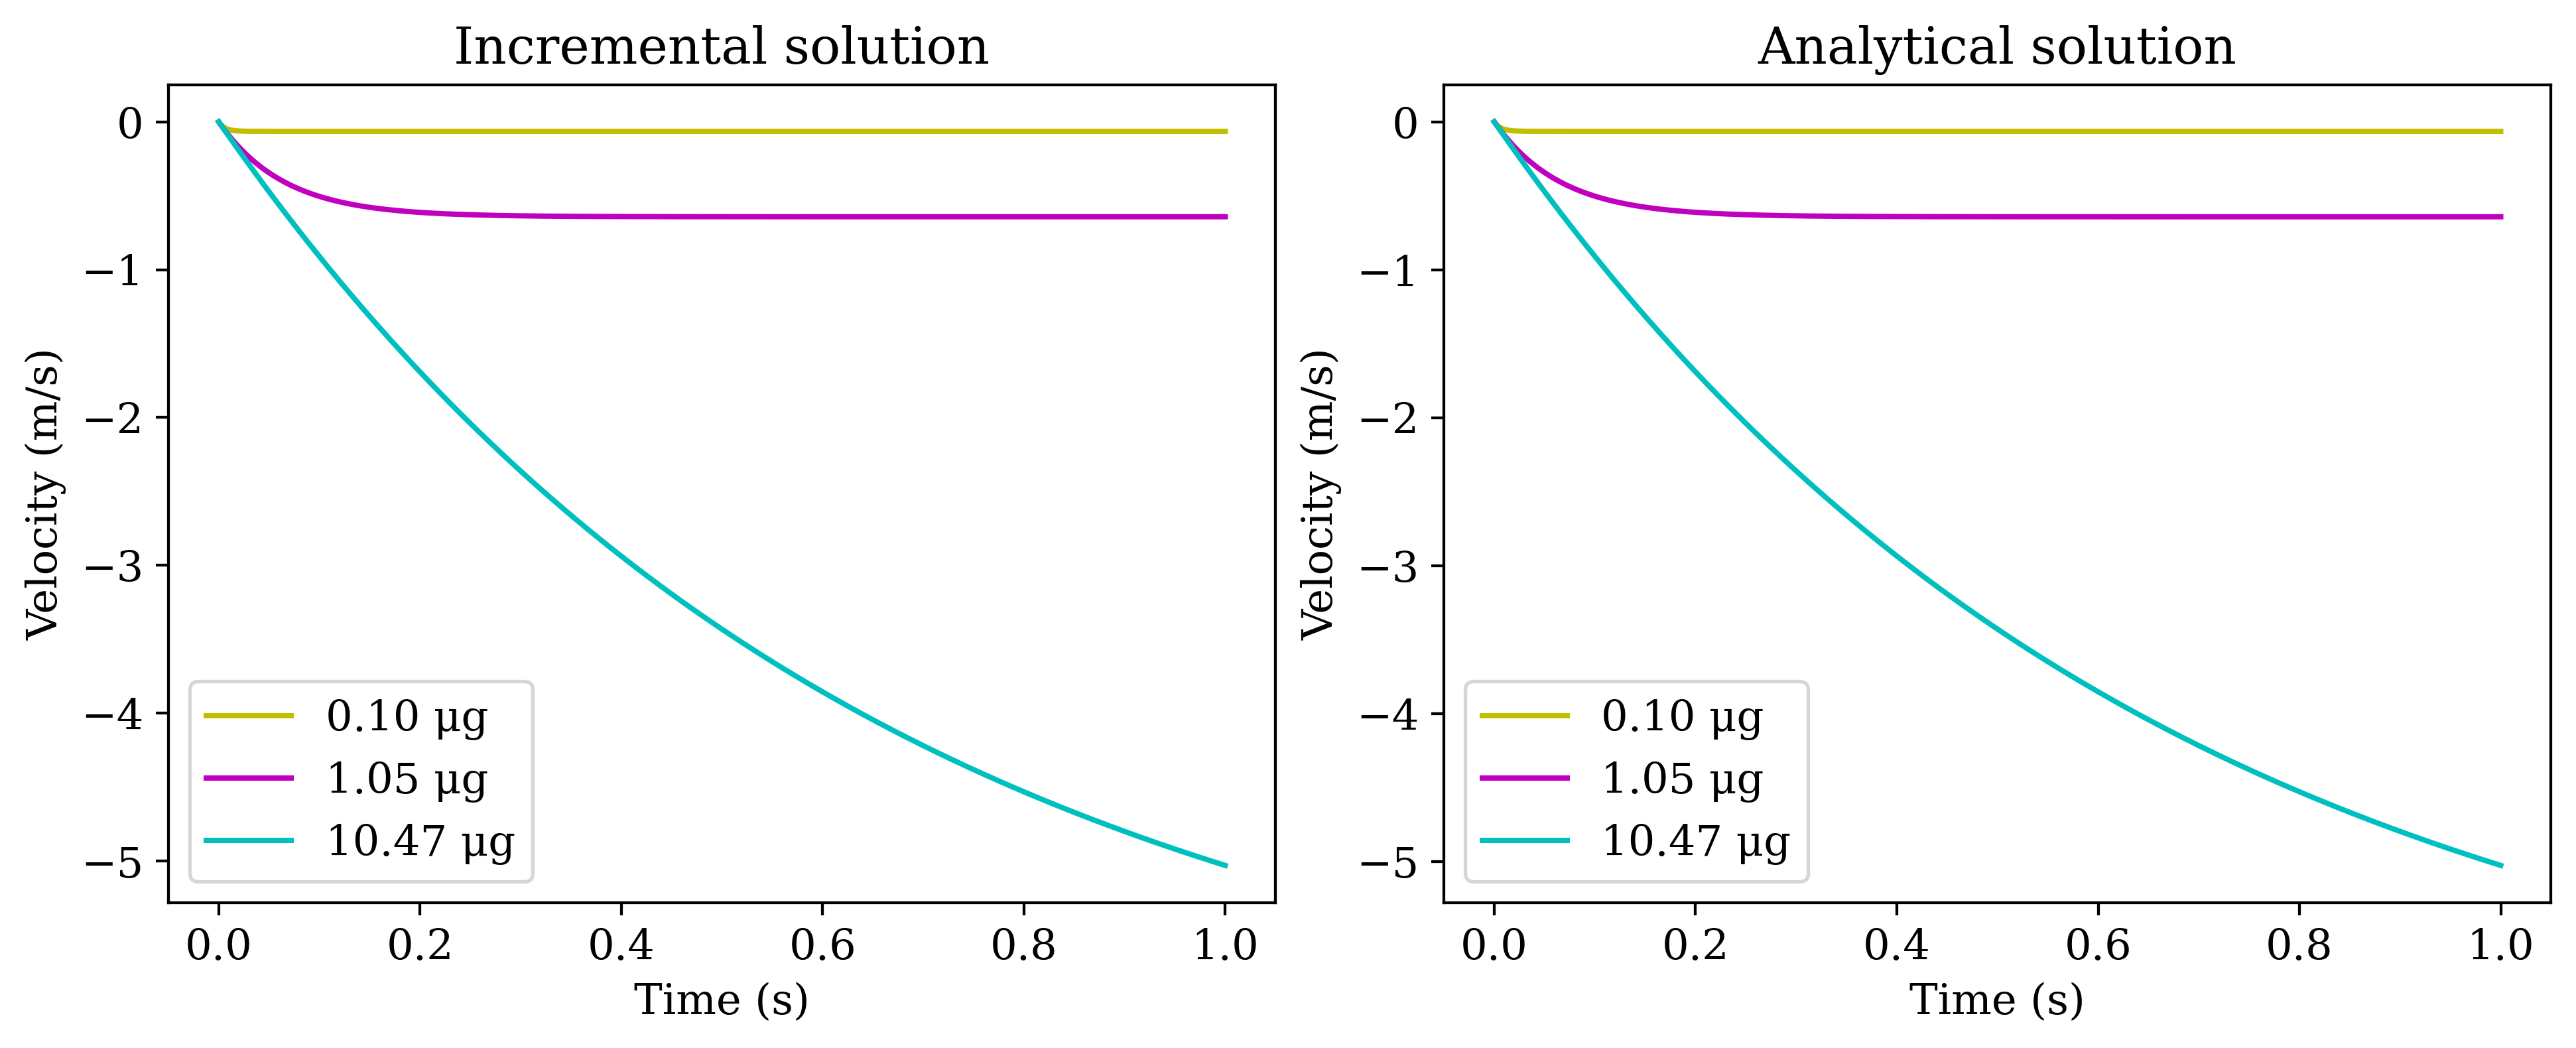

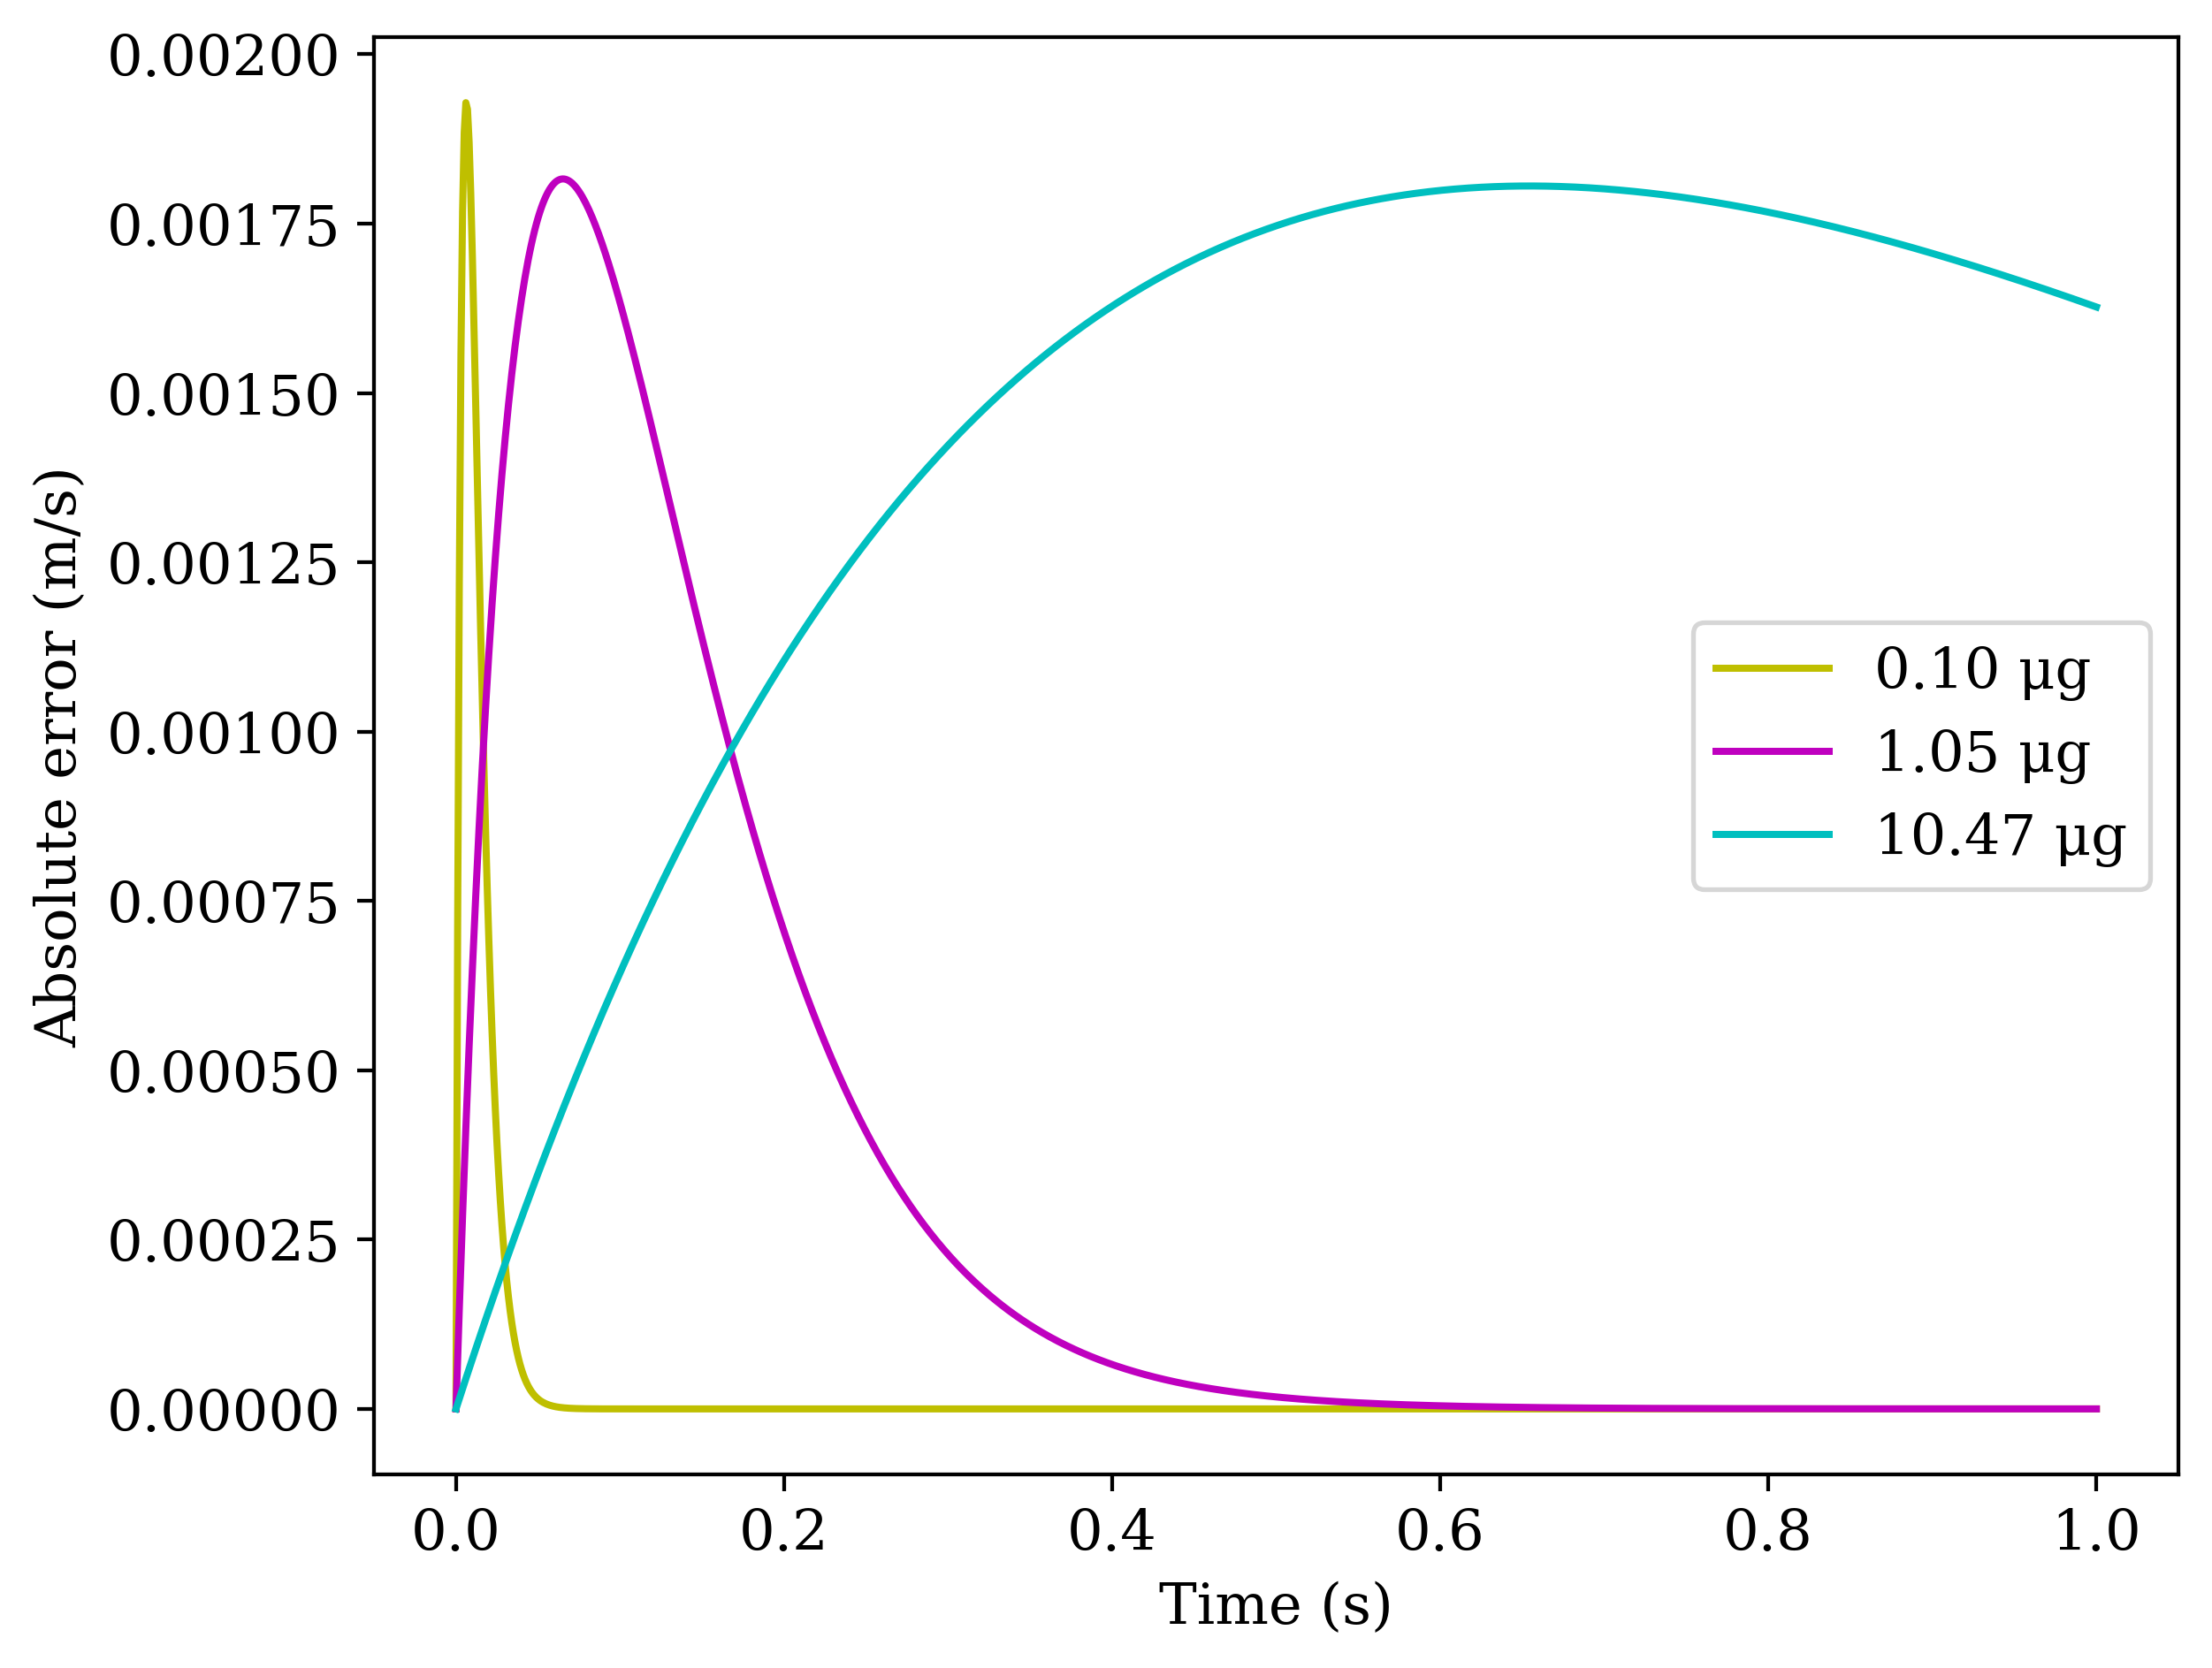

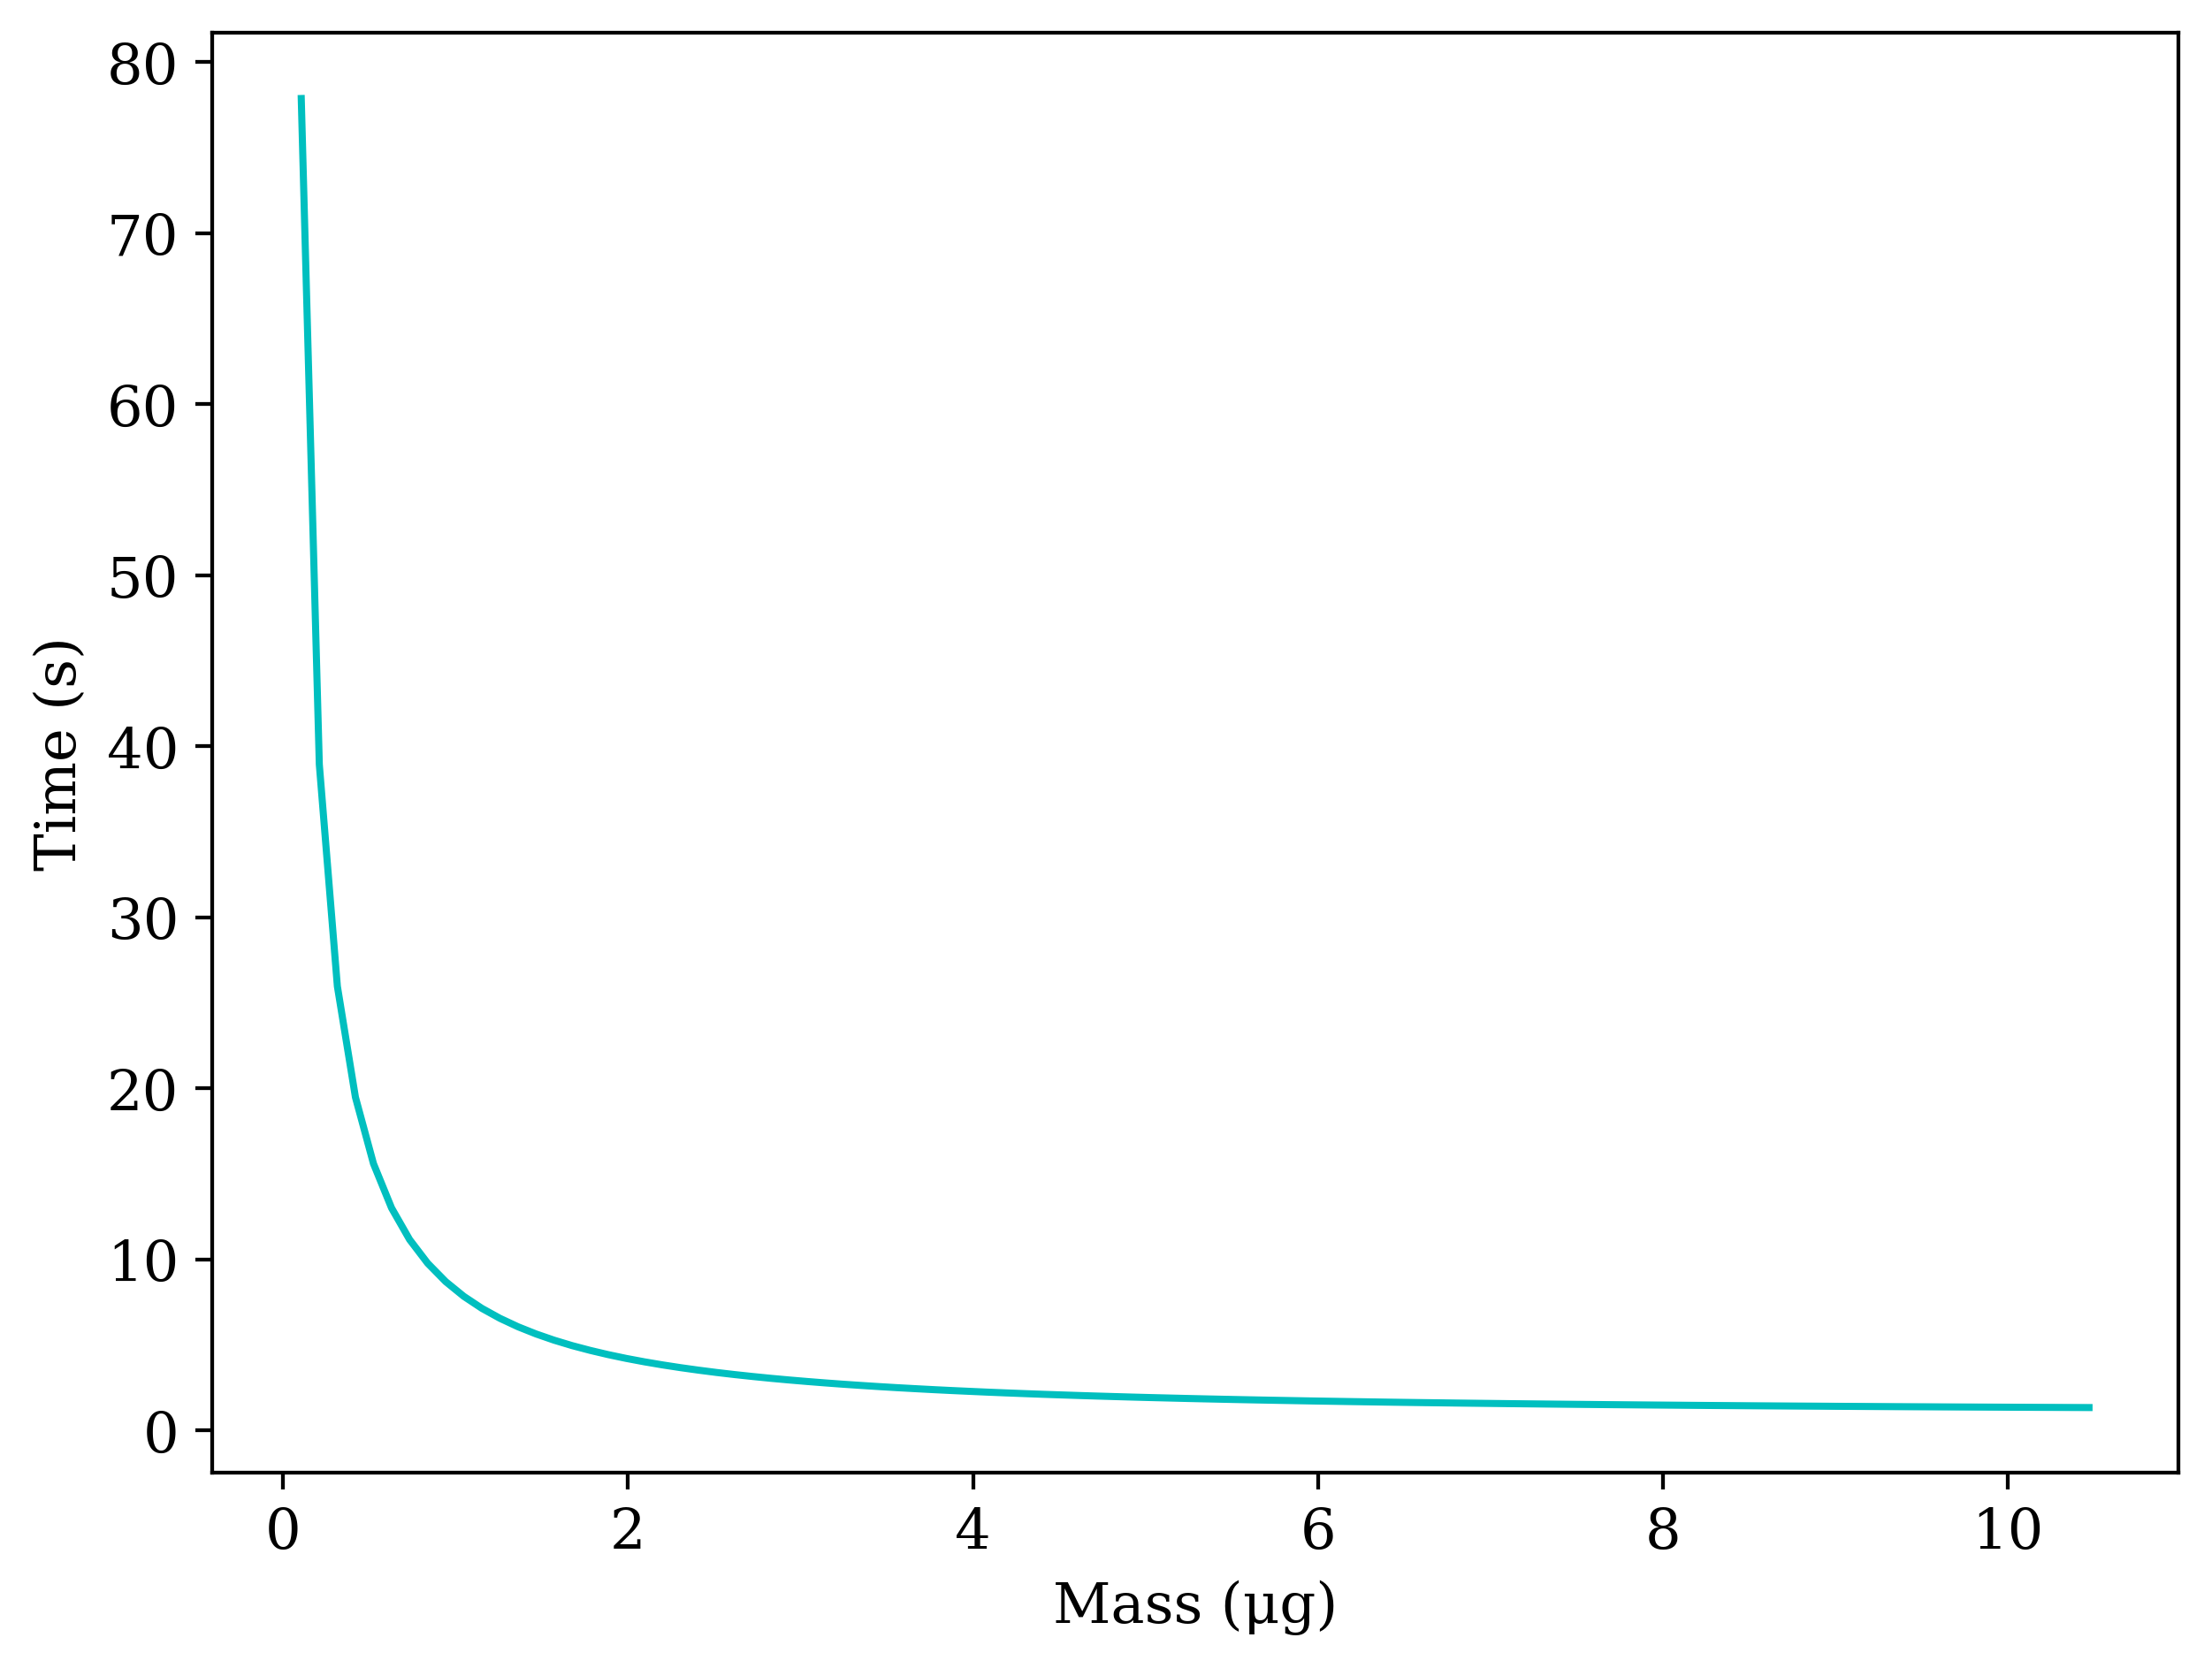

In [3]:
ρ = 2e3 # kg / m^3
D = 1e-4 # m
M = ρ * 4 * np.pi * (D/2)**3 / 3 # kg


"""Fall under the action of air resistance.
"""
def fall(m, tmax):
  t, Vy = 0, 0
  ts, Vs = [0], [0]

  while t<tmax:
    Vy += (-g - B * D * Vy / m) * dt
    t += dt

    ts.append(t)
    Vs.append(Vy)

  return ts, Vs


ms = [0.1 * M, M, 10 * M]
cs = ['y', 'm', 'c']

fig, axs = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True,
                        dpi=384)

for m, c in zip(ms, cs):
  ts, Vs = fall(m, 1)
  axs[0].plot(ts, Vs, color=c, label=f'{m/1e-9:.2f} μg')

axs[0].legend()
axs[0].set_xlabel('Time (s)')
axs[0].set_ylabel('Velocity (m/s)')
axs[0].set_title('Incremental solution')


"""Analytical solution for the fall under the action of air resistance.
"""
def analytical_fall(m, t):
  return m * g * (np.exp(-B * D * t / m) - 1) / (B * D)


ts = np.linspace(0, 1, num=1000)

for m, c in zip(ms, cs):
  Vs = [analytical_fall(m, t) for t in ts]
  axs[1].plot(ts, Vs, color=c, label=f'{m/1e-9:.2f} μg')

axs[1].legend()
axs[1].set_xlabel('Time (s)')
axs[1].set_ylabel('Velocity (m/s)')
axs[1].set_title('Analytical solution')

plt.savefig('falling_velocity.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(constrained_layout=True, dpi=384)

for m, c in zip(ms, cs):
  ts, Vs = fall(m, 1)
  Vs_a = [analytical_fall(m, t) for t in ts]
  errors = [abs(v-va) for v, va in zip(Vs, Vs_a)]
  ax.plot(ts, errors, color=c, label=f'{m/1e-9:.2f} μg')

ax.legend()
ax.set_xlabel('Time (s)')
ax.set_ylabel('Absolute error (m/s)')

plt.savefig('error_falling_velocity.png', bbox_inches='tight')
plt.show()


"""Time to fall to the ground for a given mass.
"""
def time_to_ground(m, H):
  t, Vy = 0, 0

  while H > 0:
    H += Vy * dt
    Vy += (-g - B * D * Vy / m) * dt
    t += dt

  return t


ms = np.linspace(0.1 * M, M * 10, num=100)
ts = [time_to_ground(m, 5) for m in ms]

fig, ax = plt.subplots(constrained_layout=True, dpi=384)
ax.plot(ms * 1e9, ts, 'c')
plt.xlabel('Mass (μg)')
plt.ylabel('Time (s)')
plt.savefig('fall_time.png', bbox_inches='tight')
plt.show()

# Exercise 3

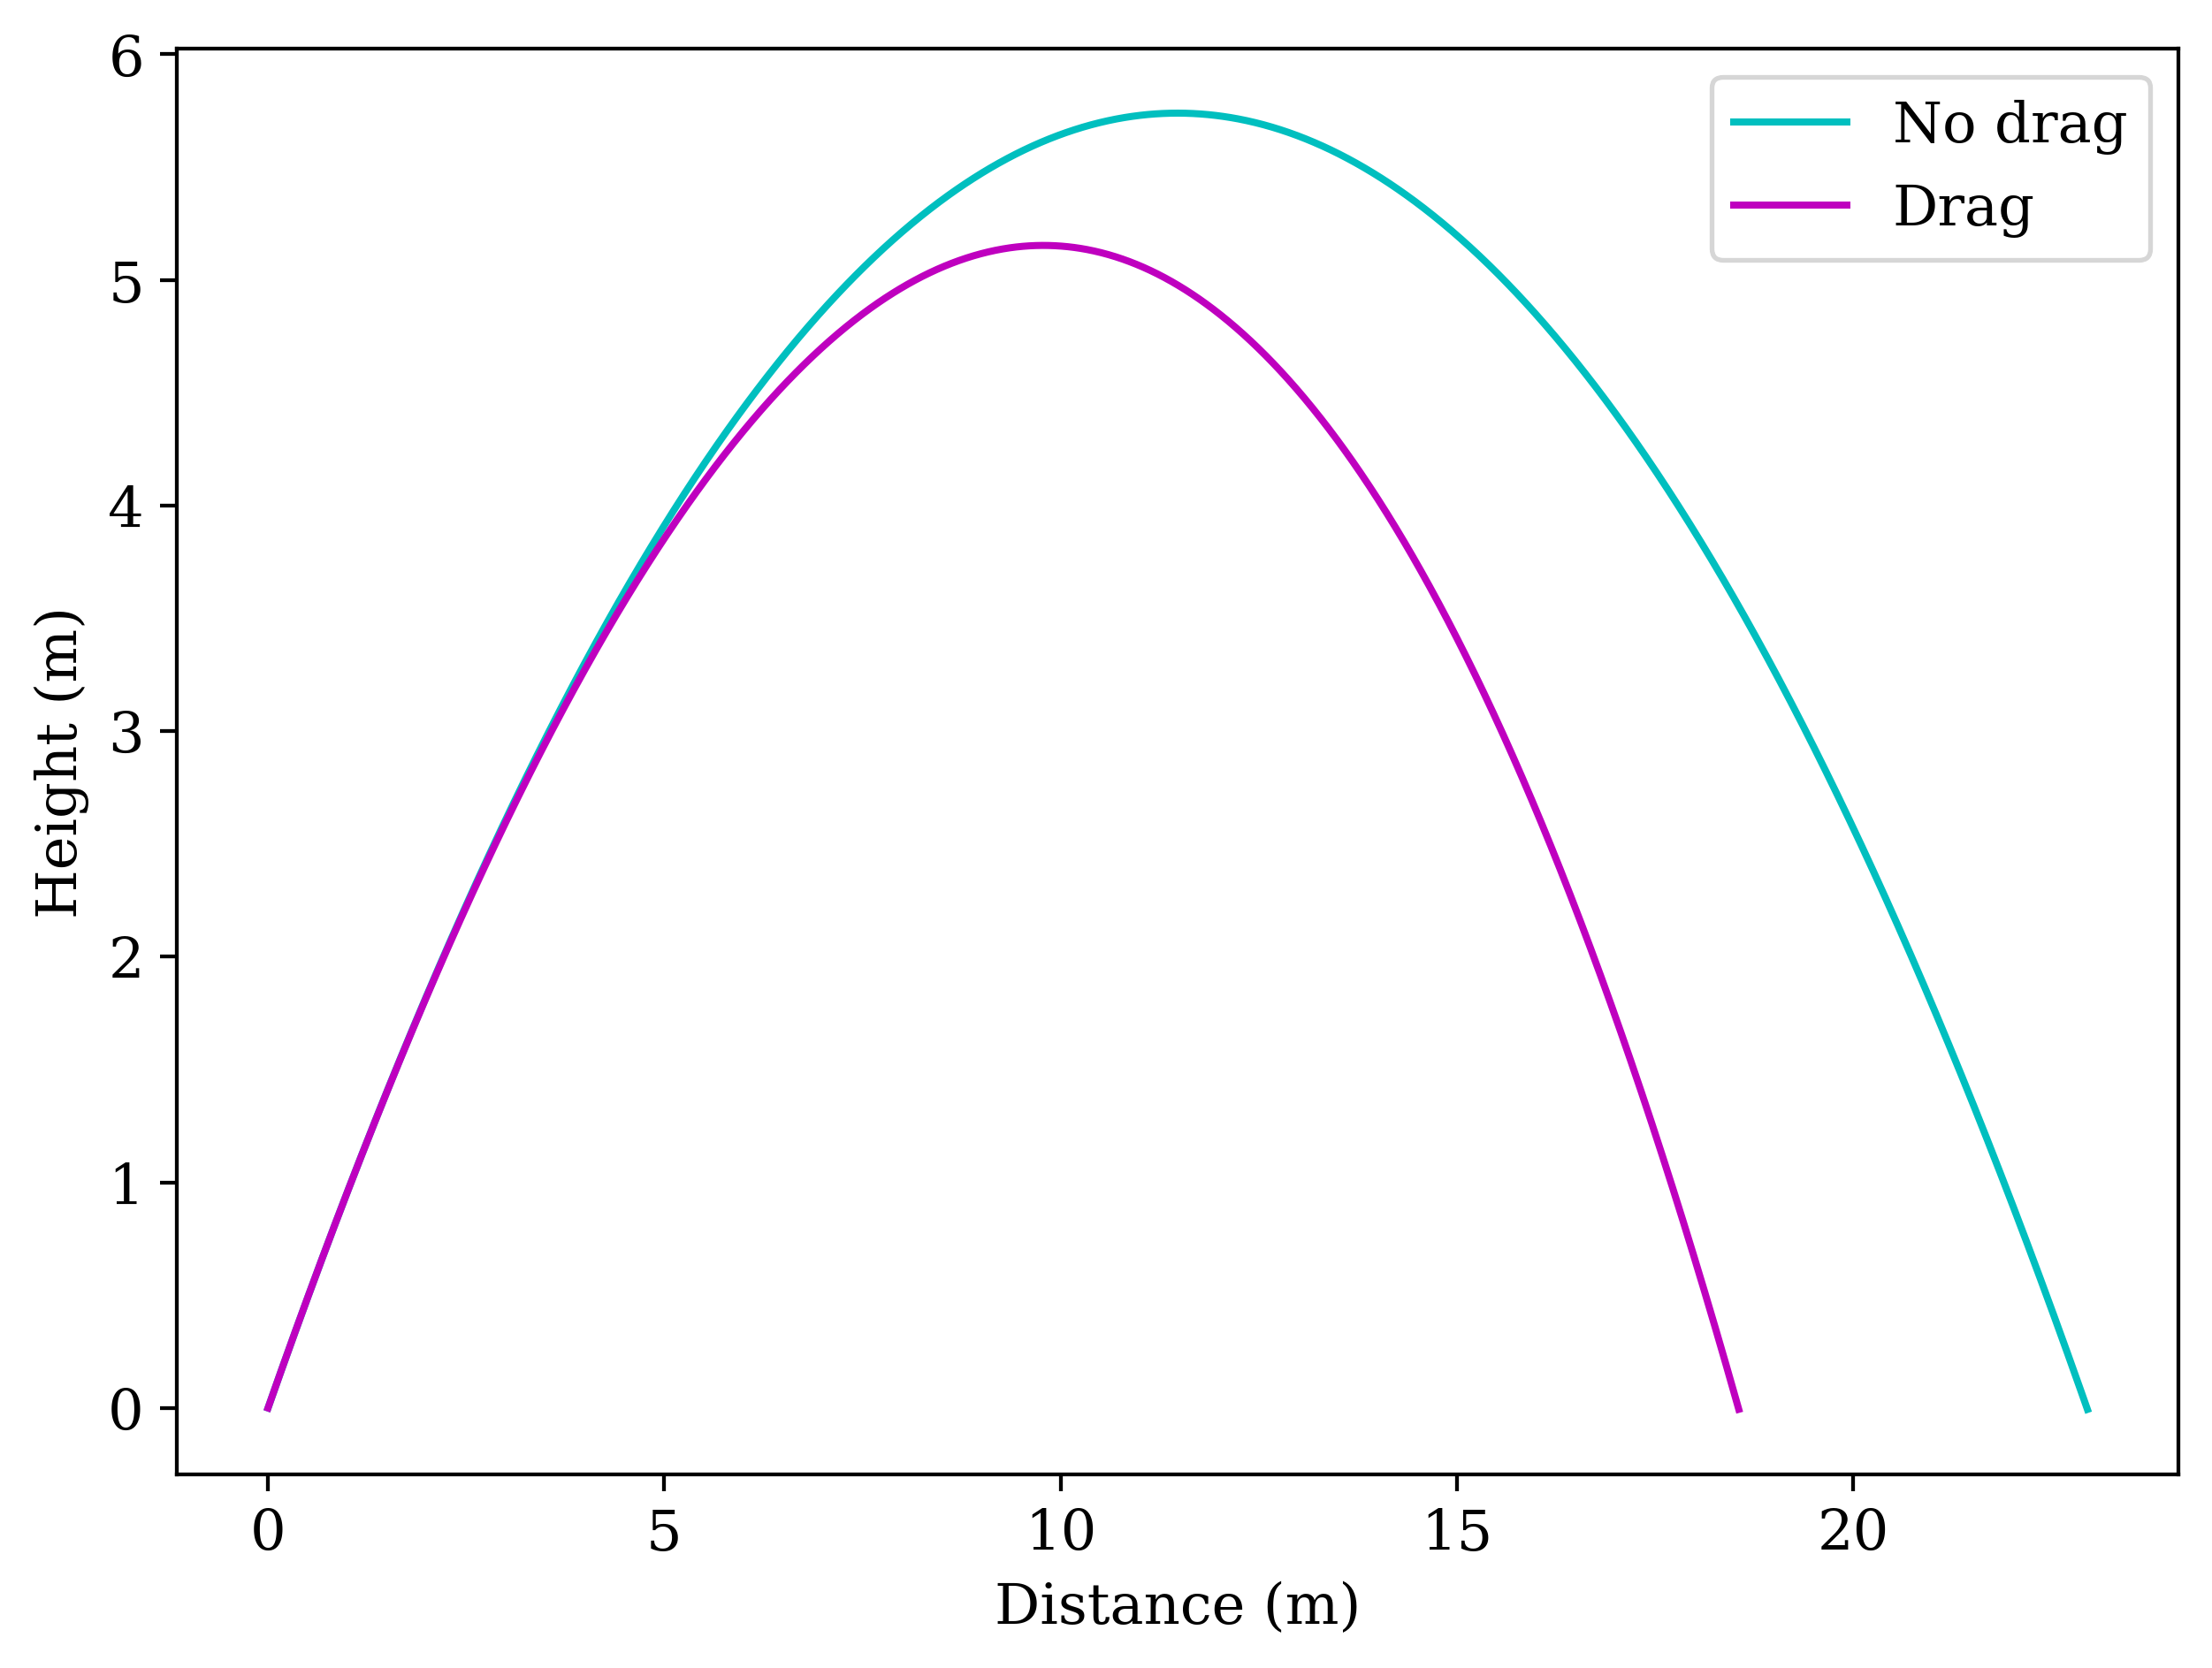

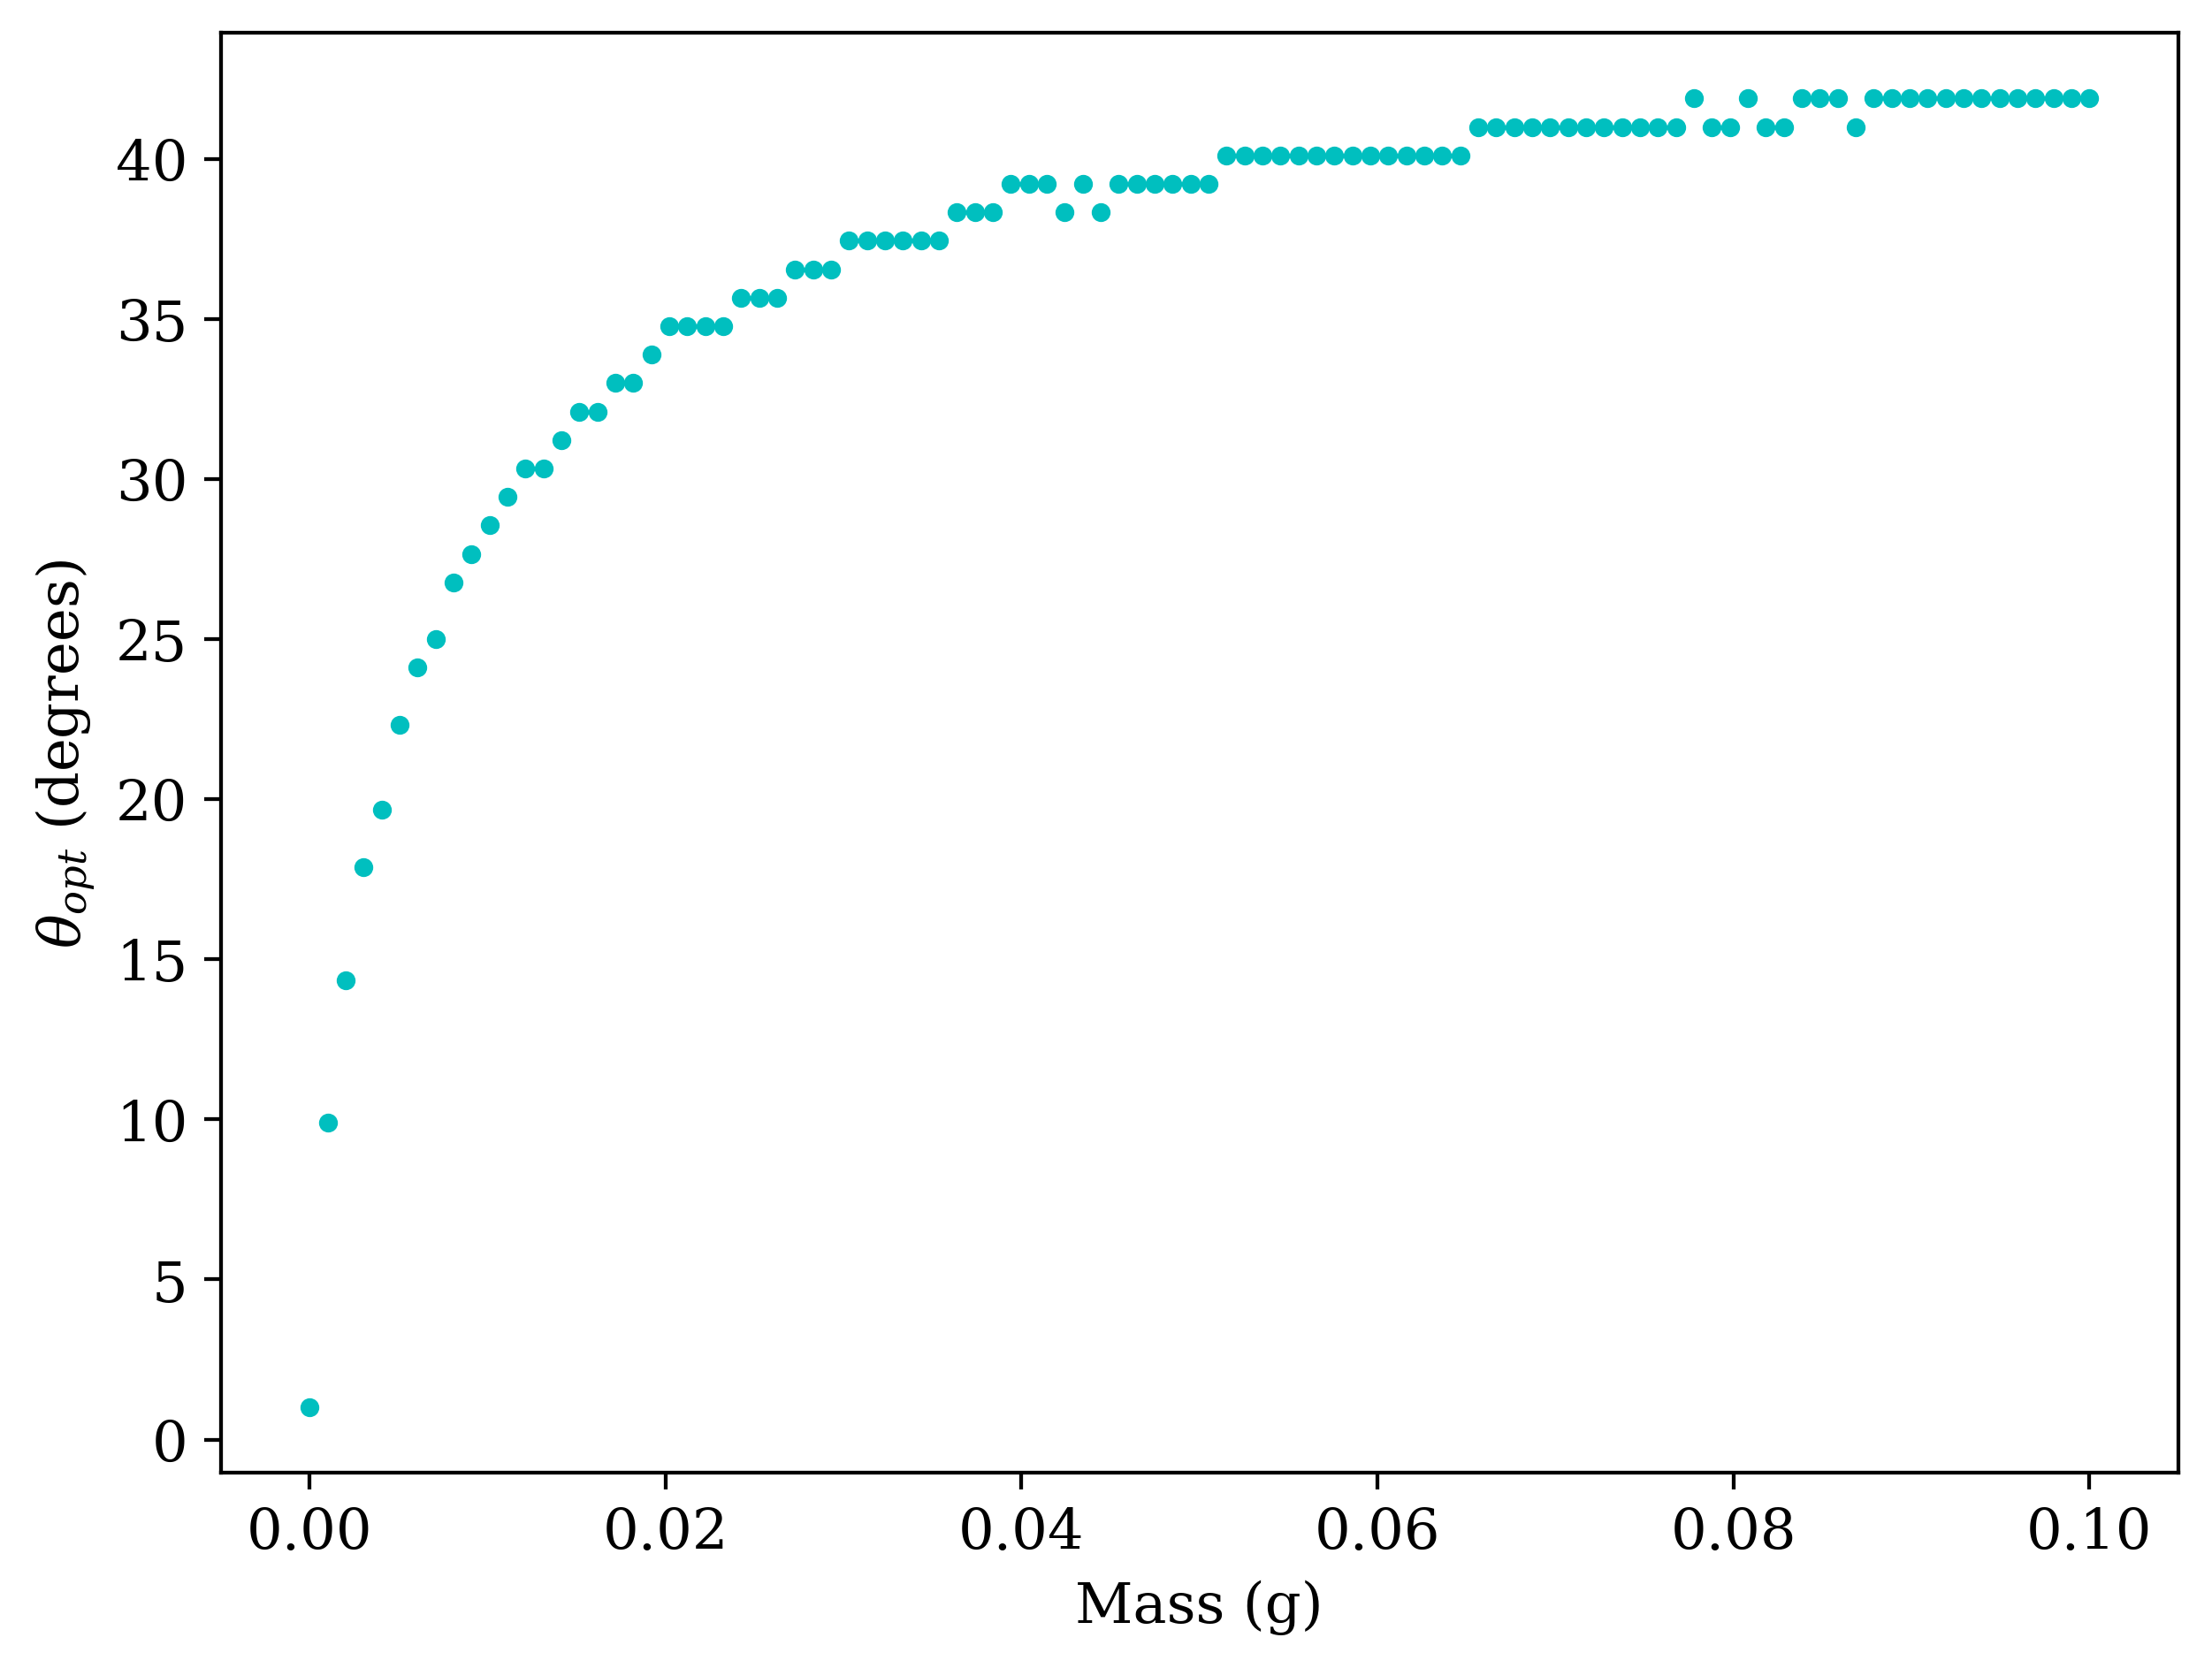

In [4]:
"""Projectile motion with air resistance.
"""
def projectile(b, m, Vx, Vy):
    t = 0
    x, y = 0, 0
    xs, ys = [x], [y]

    while y >= 0:
        x += Vx * dt
        y += Vy * dt
        Vx += -b * Vx * dt / m
        Vy += (-g - b * Vy / m) * dt
        t += dt

        xs.append(x)
        ys.append(y)

    return xs, ys


"""Projectile motion without air resistance.
"""
def no_drag_projectile(m, Vx, Vy):
  return projectile(0, m, Vx, Vy)


M = 0.0001 # kg
D = 0.1 # m
θ = 45 # degree
V = 15 # m / s

Vx = V * np.cos(θ * np.pi / 180)
Vy = V * np.sin(θ * np.pi / 180)

xs_d, ys_d = projectile(B * D, M, Vx, Vy)
xs, ys = no_drag_projectile(M, Vx, Vy)

fig, ax = plt.subplots(constrained_layout=True, dpi=384)
ax.plot(xs, ys, label='No drag', color='c')
ax.plot(xs_d, ys_d, label='Drag', color='m')
ax.legend()
plt.xlabel('Distance (m)')
plt.ylabel('Height (m)')
plt.savefig('flight_path.png', bbox_inches='tight')
plt.show()


"""Find optimum launch angle.
"""
def optimum_angle(m, D, V):
    angles = np.linspace(1, 89, 100)
    ranges = []

    for θ in angles:
        Vx = V * np.cos(θ * np.pi / 180)
        Vy = V * np.sin(θ * np.pi / 180)
        xs, _ = projectile(B * D, m, Vx, Vy)

        ranges.append(xs[-1])

    return angles[np.argmax(ranges)]


ms = np.linspace(0.0001 * M, M, num=100)
angles_opt = [optimum_angle(m, D, V) for m in ms]

fig, ax = plt.subplots(constrained_layout=True, dpi=384)
ax.plot(ms * 1000, angles_opt, 'c.')
ax.set_xlabel('Mass (g)')
ax.set_ylabel('$θ_{opt}$ (degrees)')
plt.savefig('optimum_angle.png', bbox_inches='tight')
plt.show()

# Exercise 4

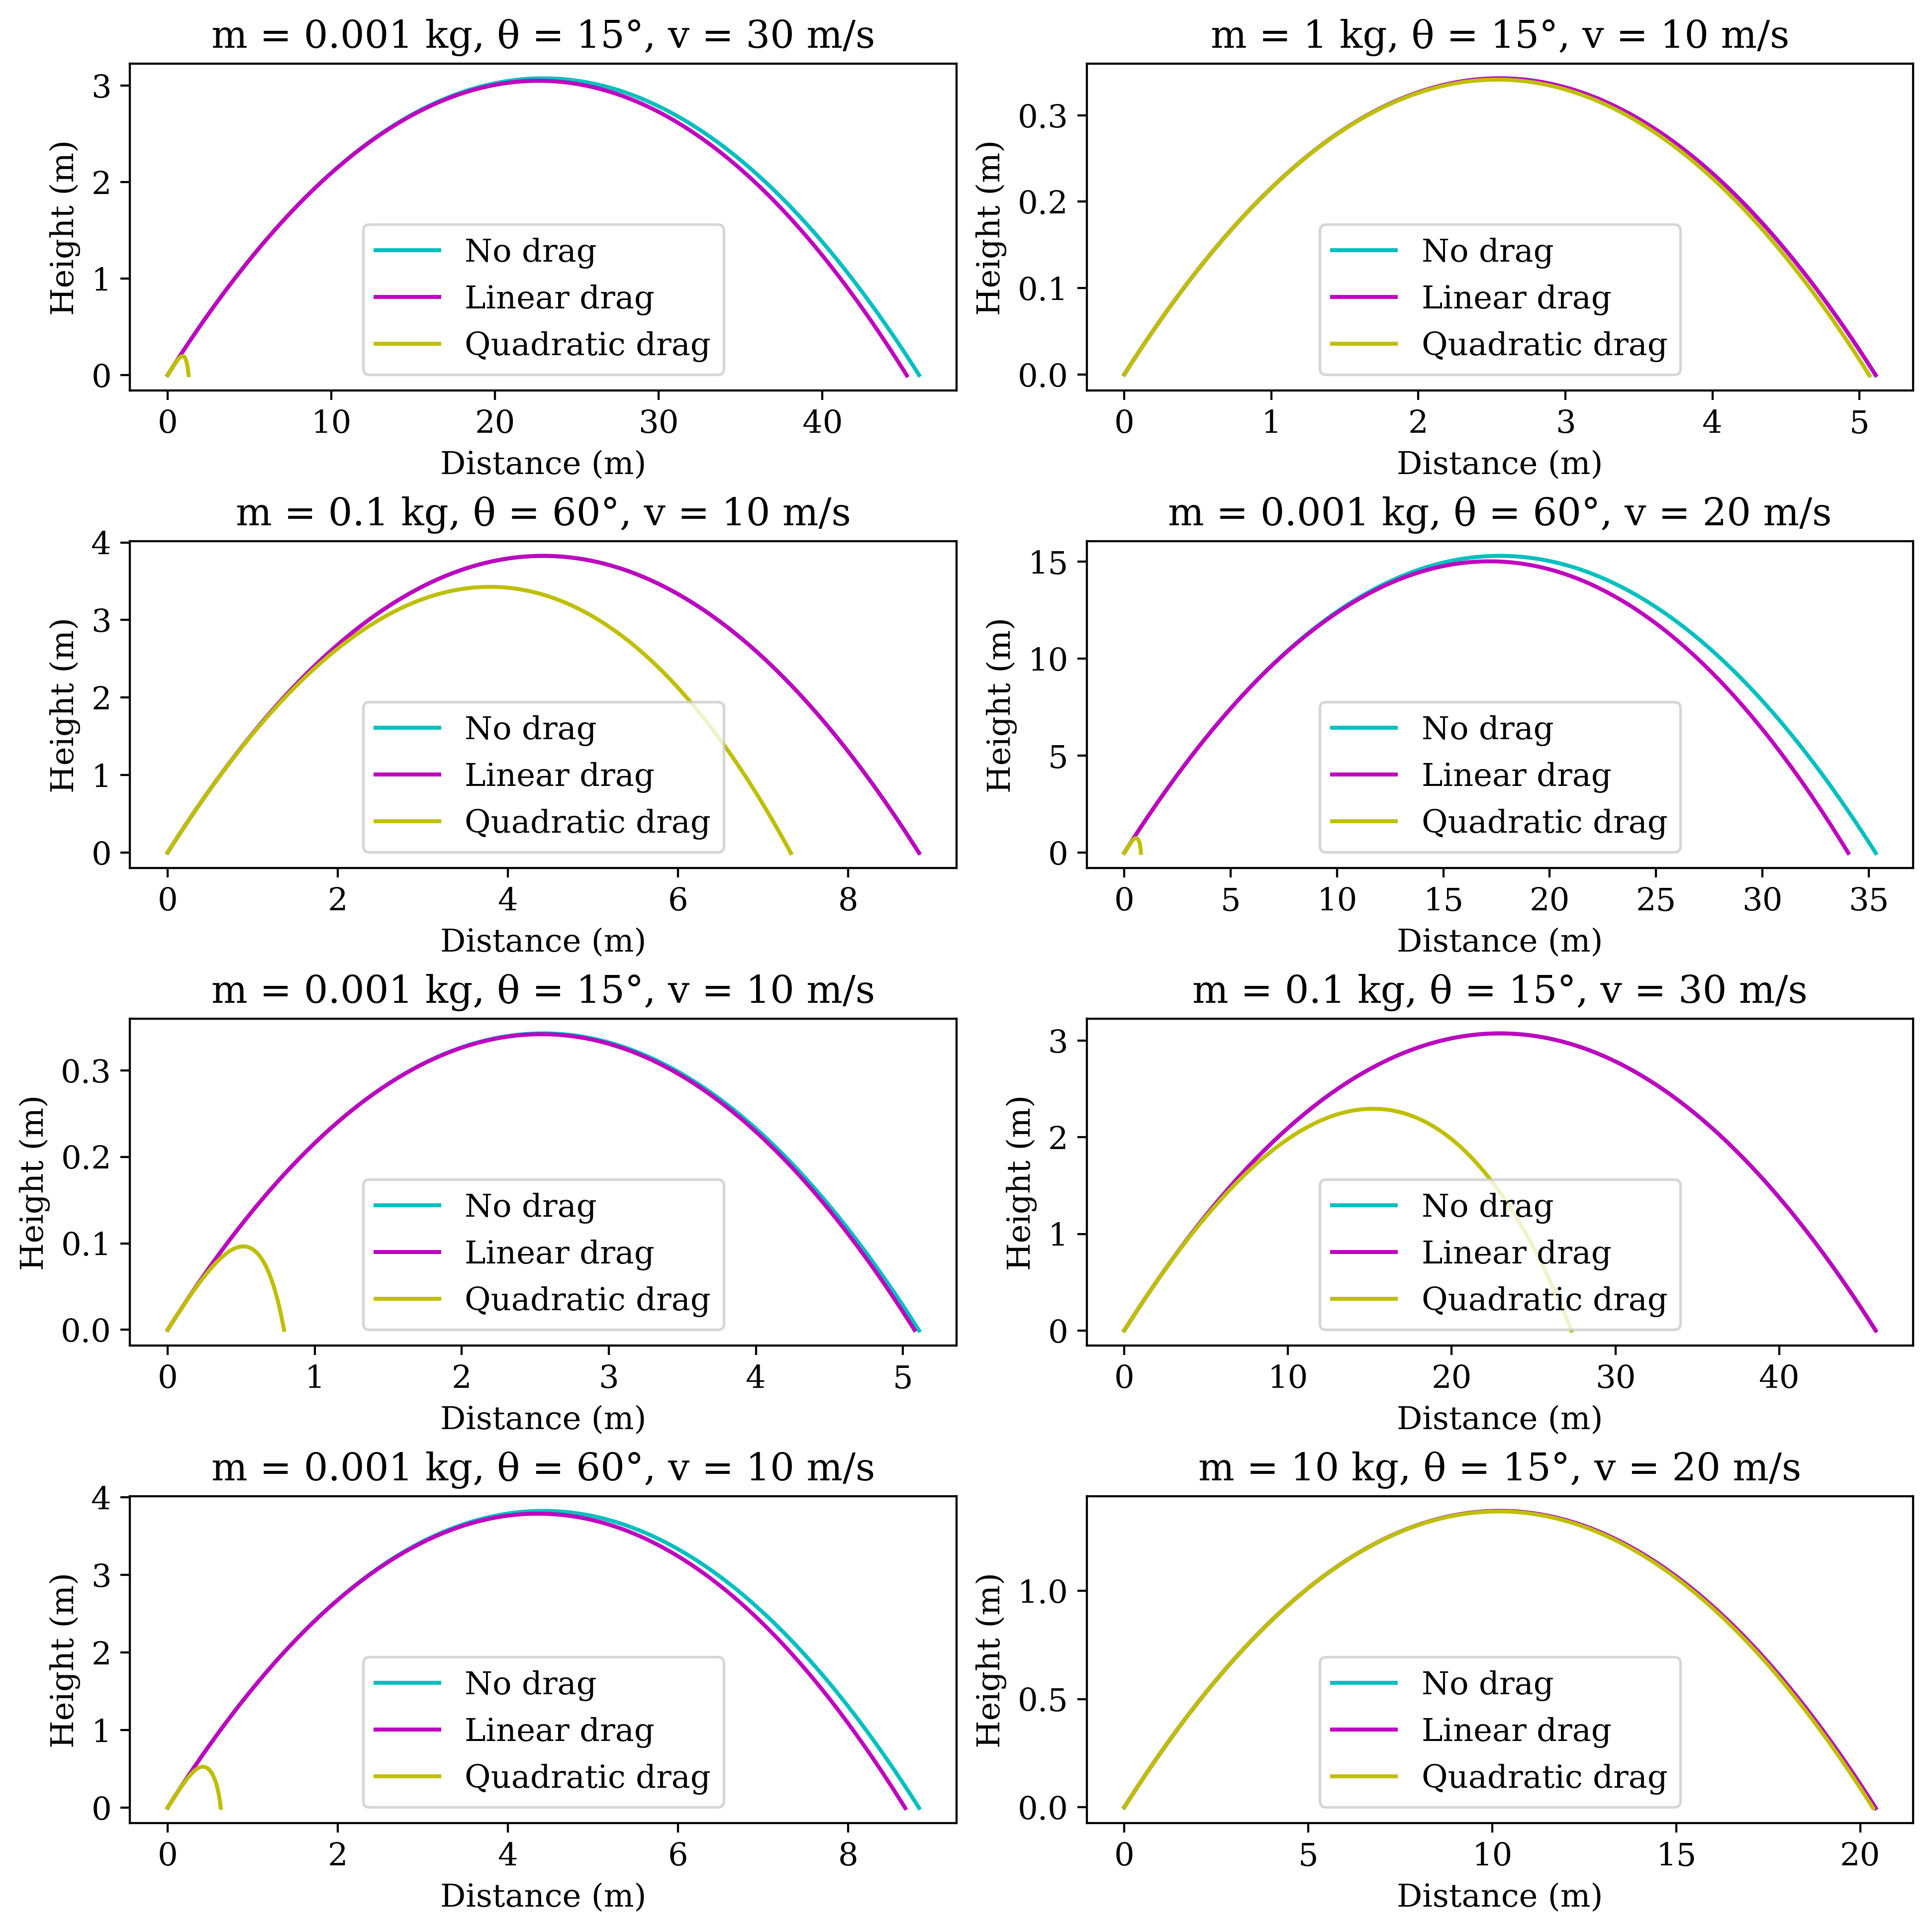

In [5]:
"""Projectile motion with quadratic air resistance.
"""
def quad_projectile(c, m, Vx, Vy):
    t = 0
    x, y = 0, 0
    xs, ys = [x], [y]

    while y >= 0:
        x += Vx * dt
        y += Vy * dt
        sqr = np.sqrt(Vx**2 + Vy**2)
        Vx += -c * Vx * dt * sqr / m
        Vy += (-g - c * Vy * sqr / m) * dt
        t += dt

        xs.append(x)
        ys.append(y)

    return xs, ys


D = 0.1 # m
Ms = [0.001, 0.1, 1, 10] # kg
θs = [15, 45, 60] # degree
Vs = [10, 20, 30] # m / s

fig, axs = plt.subplots(4, 2, figsize=(10, 10), constrained_layout=True, dpi=384)

for ax in axs.flat:
    M = choice(Ms)
    θ = choice(θs)
    V = choice(Vs)

    Vx = V * np.cos(θ * np.pi / 180)
    Vy = V * np.sin(θ * np.pi / 180)

    xs_d, ys_d = projectile(B * D, M, Vx, Vy)
    xs, ys = no_drag_projectile(M, Vx, Vy)
    xs_q, ys_q = quad_projectile(C * D**2, M, Vx, Vy)

    ax.plot(xs, ys, label='No drag', color='c')
    ax.plot(xs_d, ys_d, label='Linear drag', color='m')
    ax.plot(xs_q, ys_q, label='Quadratic drag', color='y')
    ax.legend()
    ax.set_xlabel('Distance (m)')
    ax.set_ylabel('Height (m)')
    ax.set_title(f'm = {M} kg, θ = {θ}°, v = {V} m/s')

plt.savefig('drag_comparison.png', bbox_inches='tight')
plt.show()